In [ ]:
# Phase 3: 5G网络实体识别与分类

**目的**: 基于IP地址模式和协议特征识别UE、gNB、Core等5G网络实体

**输入**: 标准化后的数据

**输出**: 实体分类和QoS标记


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from datetime import datetime
import networkx as nx
from collections import defaultdict

print("Phase 3: 5G网络实体识别与分类环境准备完成")


Phase 3: 5G网络实体识别与分类环境准备完成


In [3]:
# 从Phase 2加载时间标准化数据
print("从Phase 2加载时间标准化数据...")
df = pd.read_csv('../data/processed/time_standardized.csv')
print(f"加载数据完成: {len(df)} 条记录")

def classify_network_entities(df):
    """
    基于IP地址模式和协议特征识别5G网络实体
    """
    
    # 定义IP地址分类规则
    def classify_ip(ip_addr):
        """分类IP地址为不同的网络实体类型"""
        if pd.isna(ip_addr):
            return 'Unknown'
        
        ip_str = str(ip_addr)
        
        # UE网段识别
        if ip_str.startswith('10.155.15.'):
            return 'UE'
        # 核心网网段
        elif ip_str.startswith('10.41.150.') or ip_str.startswith('10.50.150.'):
            return 'Core'
        # gNB网段 (推测)
        elif ip_str.startswith('10.') and not ip_str.startswith(('10.155.15.', '10.41.150.', '10.50.150.')):
            return 'gNB'
        # 外部网络
        elif ip_str.startswith(('109.105.', '142.250.', '193.166.')):
            return 'External'
        # 内网其他
        elif ip_str.startswith('10.') or ip_str.startswith('192.168.') or ip_str.startswith('172.'):
            return 'Internal'
        else:
            return 'External'
    
    # 对源地址和目标地址进行分类
    df['SrcAddr_Type'] = df['SrcAddr'].apply(classify_ip)
    df['DstAddr_Type'] = df['DstAddr'].apply(classify_ip)
    
    # 基于协议和端口进一步分类
    def refine_classification(row):
        """基于协议和端口信息进一步细化分类"""
        if row['Proto_normalized'] == 'SCTP':
            # SCTP通常是5G信令，可能是AMF、SMF等核心网功能
            if row['SrcAddr_Type'] == 'Core' or row['DstAddr_Type'] == 'Core':
                return 'Core_Signaling'
        
        # HTTP/HTTPS流量
        if row['Sport'] in [80, 443, 8080] or row['Dport'] in [80, 443, 8080]:
            return 'Web_Service'
        
        return row['SrcAddr_Type']
    
    # 细化源地址分类
    df['SrcAddr_Type_Refined'] = df.apply(refine_classification, axis=1)
    
    return df

# 执行实体分类
print("\\n执行5G网络实体分类...")
df = classify_network_entities(df)
print("实体分类完成")

# 统计实体分类结果
print("\\n=== 源地址Entity Classification Statistics ===")
src_type_counts = df['SrcAddr_Type'].value_counts()
print(src_type_counts)

print("\\n=== 目标地址Entity Classification Statistics ===")
dst_type_counts = df['DstAddr_Type'].value_counts()
print(dst_type_counts)

print("\\n=== 细化分类统计 ===")
refined_counts = df['SrcAddr_Type_Refined'].value_counts()
print(refined_counts)


从Phase 2加载时间标准化数据...


/tmp/ipykernel_2449335/1053124687.py:3: DtypeWarning: Columns (24,28,36,96,97,109,115) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/processed/time_standardized.csv')


加载数据完成: 1215890 条记录
\n执行5G网络实体分类...
实体分类完成
\n=== 源地址Entity Classification Statistics ===
SrcAddr_Type
UE          1050664
gNB          113950
Core          34496
External      16753
Internal         27
Name: count, dtype: int64
\n=== 目标地址Entity Classification Statistics ===
DstAddr_Type
Core        1134879
UE            44010
External      31451
gNB            5024
Internal        526
Name: count, dtype: int64
\n=== 细化分类统计 ===
SrcAddr_Type_Refined
UE                1050664
gNB                113161
Core                30958
External            16753
Core_Signaling       4327
Internal               27
Name: count, dtype: int64


\n执行网络拓扑分析...
=== 通信模式统计 ===
   SrcAddr_Type DstAddr_Type  flow_count
8            UE         Core     1019682
11          gNB         Core      113043
9            UE     External       30496
1          Core           UE       27639
4      External           UE       16356
2          Core          gNB        4703
0          Core         Core        2154
12          gNB     External         754
10           UE     Internal         486
3      External     External         201
5      External          gNB         196
14          gNB          gNB         125
13          gNB     Internal          28
7      Internal           UE          15
6      Internal     Internal          12
\n=== 攻击目标分析 ===
      Attack Type DstAddr_Type  attack_count
6        UDPFlood         Core        457340
0       HTTPFlood         Core        140812
4     SlowrateDoS         Core         73124
5  TCPConnectScan         Core         20052
3         SYNScan         Core         20043
7         UDPScan         Co

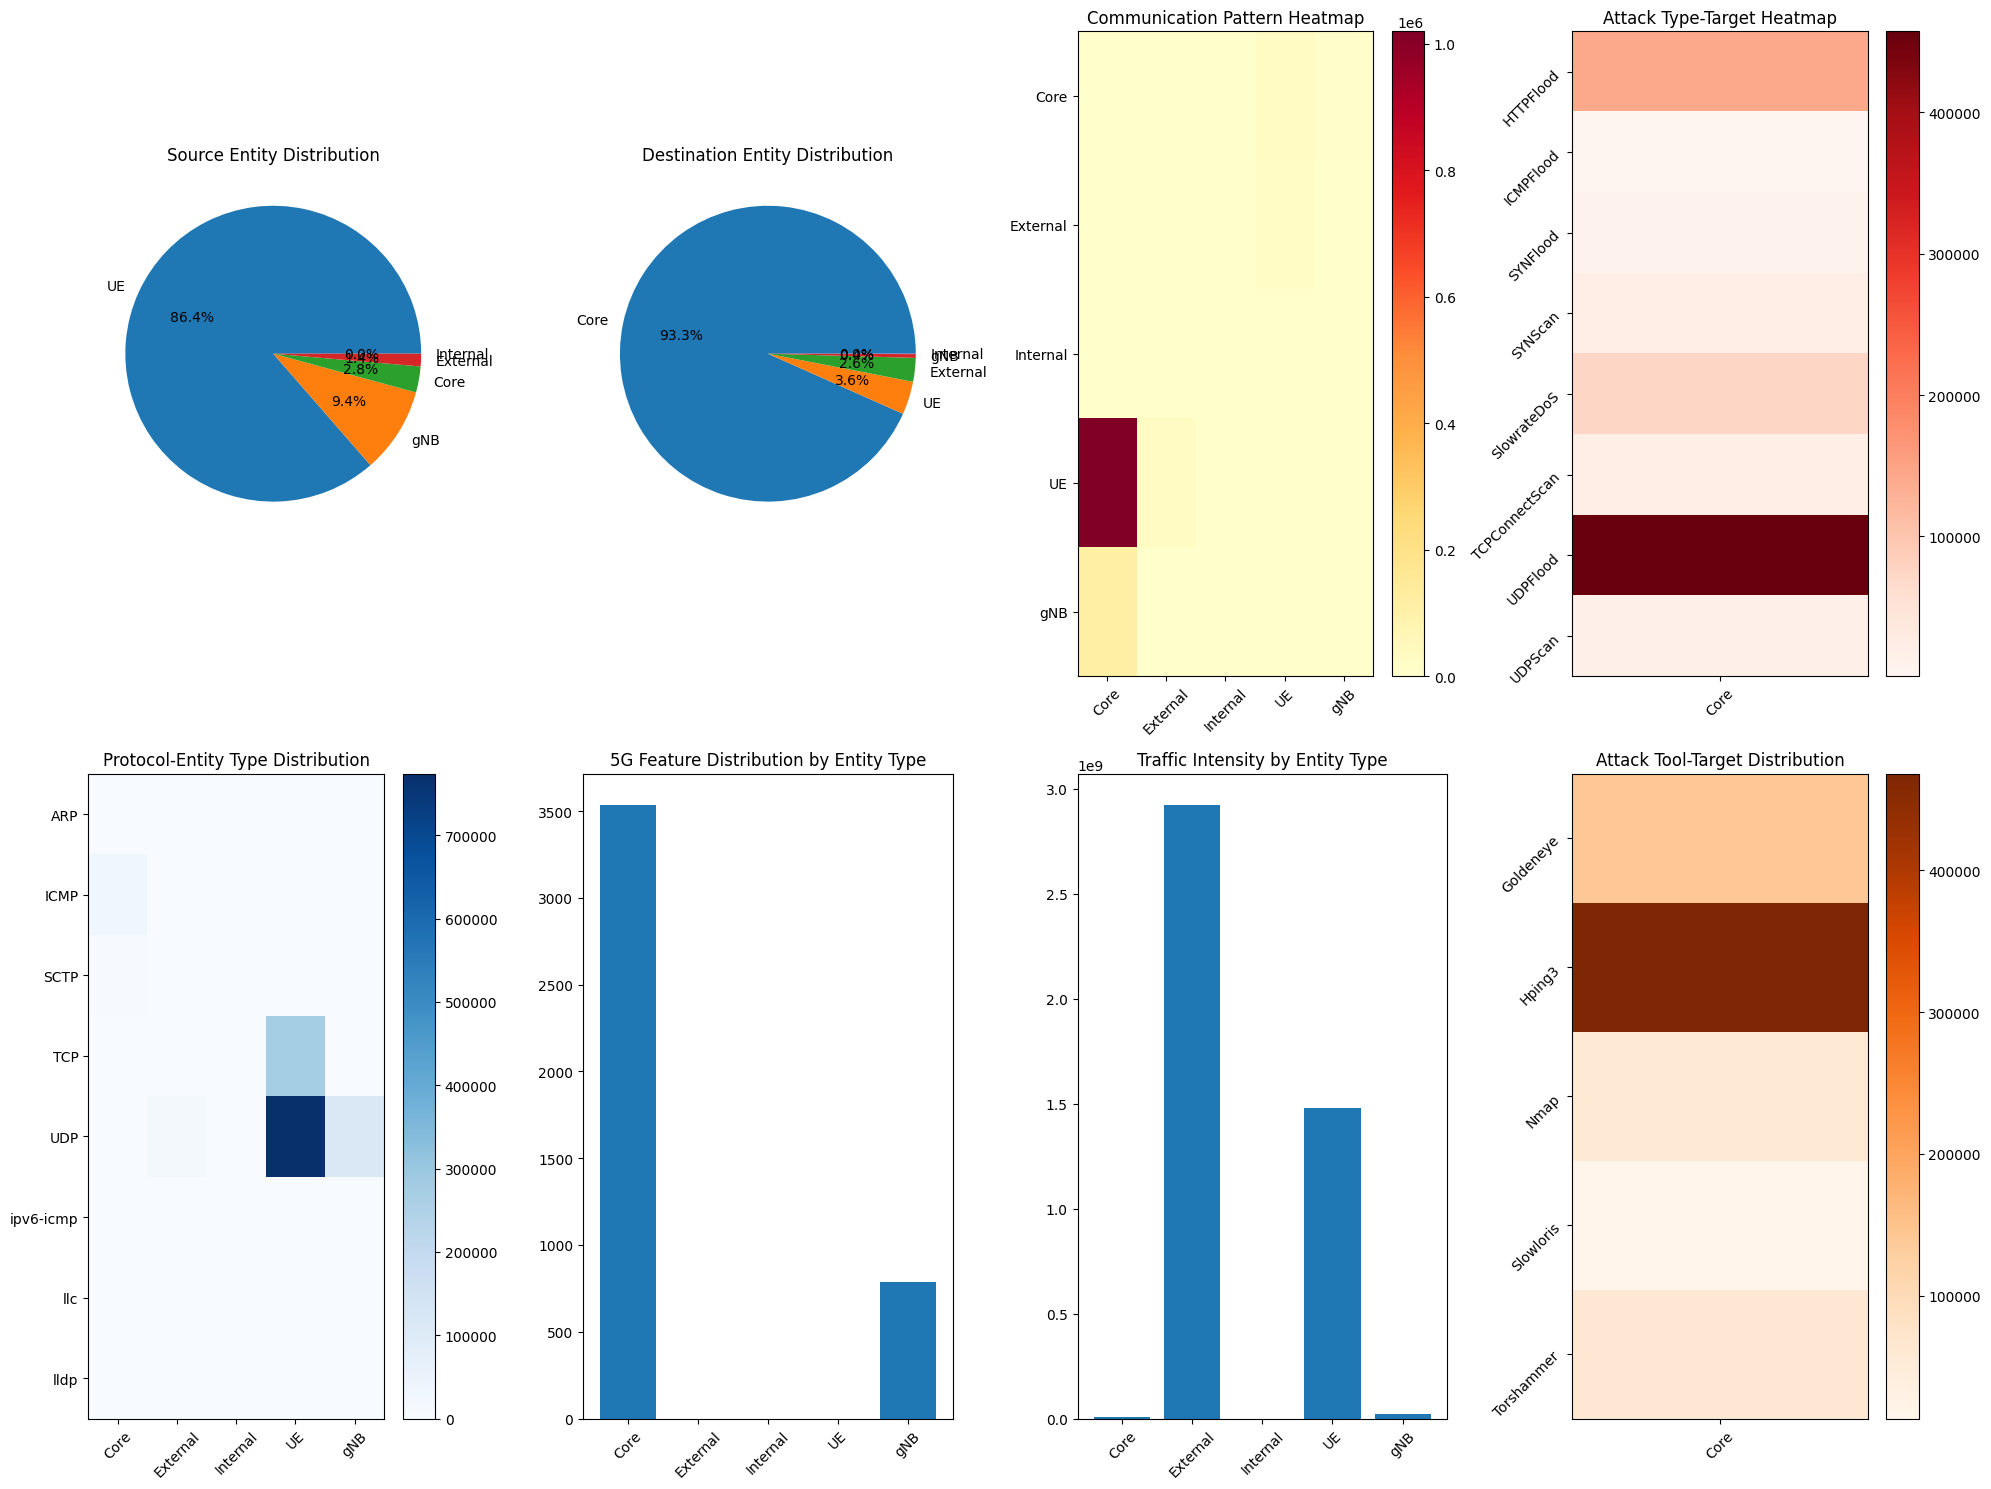

In [5]:
# 构建网络拓扑图分析
def analyze_network_topology(df):
    """分析网络拓扑结构"""
    
    # 统计通信模式
    communication_patterns = df.groupby(['SrcAddr_Type', 'DstAddr_Type']).size().reset_index(name='flow_count')
    print("=== 通信模式统计 ===")
    print(communication_patterns.sort_values('flow_count', ascending=False))
    
    # 分析攻击流量的目标实体
    attack_flows = df[df['Attack Type'] != 'Benign']
    attack_targets = attack_flows.groupby(['Attack Type', 'DstAddr_Type']).size().reset_index(name='attack_count')
    print("\\n=== 攻击目标分析 ===")
    print(attack_targets.sort_values('attack_count', ascending=False))
    
    return communication_patterns, attack_targets, attack_flows

# 执行网络拓扑分析
print("\\n执行网络拓扑分析...")
communication_patterns, attack_targets, attack_flows = analyze_network_topology(df)

# 可视化分析结果
plt.figure(figsize=(20, 15))

# 1. Entity Type Distribution
plt.subplot(2, 4, 1)
src_counts = df['SrcAddr_Type'].value_counts()
plt.pie(src_counts.values, labels=src_counts.index, autopct='%1.1f%%')
plt.title('Source Entity Distribution')

plt.subplot(2, 4, 2)
dst_counts = df['DstAddr_Type'].value_counts()
plt.pie(dst_counts.values, labels=dst_counts.index, autopct='%1.1f%%')
plt.title('Destination Entity Distribution')

# 3. 通信模式热力图
plt.subplot(2, 4, 3)
comm_matrix = communication_patterns.pivot(index='SrcAddr_Type', columns='DstAddr_Type', values='flow_count').fillna(0)
plt.imshow(comm_matrix.values, cmap='YlOrRd', aspect='auto')
plt.colorbar()
plt.title('Communication Pattern Heatmap')
plt.xticks(range(len(comm_matrix.columns)), comm_matrix.columns, rotation=45)
plt.yticks(range(len(comm_matrix.index)), comm_matrix.index)

# 4. 攻击类型 vs 目标实体
plt.subplot(2, 4, 4)
if len(attack_targets) > 0:
    attack_pivot = attack_targets.pivot(index='Attack Type', columns='DstAddr_Type', values='attack_count').fillna(0)
    plt.imshow(attack_pivot.values, cmap='Reds', aspect='auto')
    plt.colorbar()
    plt.title('Attack Type-Target Heatmap')
    plt.xticks(range(len(attack_pivot.columns)), attack_pivot.columns, rotation=45)
    plt.yticks(range(len(attack_pivot.index)), attack_pivot.index, rotation=45)

# 5. 协议 vs 实体类型
plt.subplot(2, 4, 5)
proto_entity = df.groupby(['Proto_normalized', 'SrcAddr_Type']).size().unstack(fill_value=0)
plt.imshow(proto_entity.values, cmap='Blues', aspect='auto')
plt.colorbar()
plt.title('Protocol-Entity Type Distribution')
plt.xticks(range(len(proto_entity.columns)), proto_entity.columns, rotation=45)
plt.yticks(range(len(proto_entity.index)), proto_entity.index)

# 6. 5G特征 vs 实体类型
plt.subplot(2, 4, 6)
feature_entity = df.groupby(['has_5g_features', 'SrcAddr_Type']).size().unstack(fill_value=0)
plt.bar(range(len(feature_entity.columns)), feature_entity.loc[True] if True in feature_entity.index else [0]*len(feature_entity.columns))
plt.title('5G Feature Distribution by Entity Type')
plt.xticks(range(len(feature_entity.columns)), feature_entity.columns, rotation=45)

# 7. 流量强度分布
plt.subplot(2, 4, 7)
entity_bytes = df.groupby('SrcAddr_Type')['TotBytes'].sum()
plt.bar(entity_bytes.index, entity_bytes.values)
plt.title('Traffic Intensity by Entity Type')
plt.xticks(rotation=45)

# 8. 攻击工具 vs 实体类型
plt.subplot(2, 4, 8)
tool_entity = attack_flows.groupby(['Attack Tool', 'DstAddr_Type']).size().unstack(fill_value=0)
if len(tool_entity) > 0:
    plt.imshow(tool_entity.values, cmap='Oranges', aspect='auto')
    plt.colorbar()
    plt.title('Attack Tool-Target Distribution')
    plt.xticks(range(len(tool_entity.columns)), tool_entity.columns, rotation=45)
    plt.yticks(range(len(tool_entity.index)), tool_entity.index, rotation=45)

plt.tight_layout()
plt.savefig('../data/processed/metadata/network_topology.png', dpi=300, bbox_inches='tight')
plt.show()


In [6]:
# 保存实体分类后的数据
print("\\n保存实体分类后的数据...")
df.to_csv('../data/processed/entity_classified.csv', index=False)
print(f"实体分类数据已保存: {len(df)} 条记录")

# 生成实体分类报告
entity_report = {
    "timestamp": datetime.now().isoformat(),
    "total_records": len(df),
    "src_entity_distribution": df['SrcAddr_Type'].value_counts().to_dict(),
    "dst_entity_distribution": df['DstAddr_Type'].value_counts().to_dict(),
    "refined_classification": df['SrcAddr_Type_Refined'].value_counts().to_dict(),
    "communication_patterns": communication_patterns.to_dict('records'),
    "attack_targets": attack_targets.to_dict('records') if len(attack_targets) > 0 else [],
    "unique_src_ips": df['SrcAddr'].nunique(),
    "unique_dst_ips": df['DstAddr'].nunique(),
    "ue_flows": int((df['SrcAddr_Type'] == 'UE').sum()),
    "core_flows": int((df['SrcAddr_Type'] == 'Core').sum()),
    "gnb_flows": int((df['SrcAddr_Type'] == 'gNB').sum()),
    "external_flows": int((df['SrcAddr_Type'] == 'External').sum()),
    "attack_flows_by_target": {
        "UE": int((attack_flows['DstAddr_Type'] == 'UE').sum()) if 'attack_flows' in locals() else 0,
        "Core": int((attack_flows['DstAddr_Type'] == 'Core').sum()) if 'attack_flows' in locals() else 0,
        "gNB": int((attack_flows['DstAddr_Type'] == 'gNB').sum()) if 'attack_flows' in locals() else 0,
        "External": int((attack_flows['DstAddr_Type'] == 'External').sum()) if 'attack_flows' in locals() else 0
    }
}

with open('../data/processed/metadata/entity_classification_report.json', 'w', encoding='utf-8') as f:
    json.dump(entity_report, f, indent=2, ensure_ascii=False)

print("\\n✓ Phase 3 完成:")
print(f"  - 实体分类数据: ../data/processed/entity_classified.csv")
print(f"  - 分类报告: ../data/processed/metadata/entity_classification_report.json")
print(f"  - 网络拓扑图: ../data/processed/metadata/network_topology.png")
print(f"\\n实体分类摘要:")
print(f"  - UE流量: {entity_report['ue_flows']:,} 条")
print(f"  - 核心网流量: {entity_report['core_flows']:,} 条") 
print(f"  - gNB流量: {entity_report['gnb_flows']:,} 条")
print(f"  - 外部流量: {entity_report['external_flows']:,} 条")


\n保存实体分类后的数据...
实体分类数据已保存: 1215890 条记录
\n✓ Phase 3 完成:
  - 实体分类数据: ../data/processed/entity_classified.csv
  - 分类报告: ../data/processed/metadata/entity_classification_report.json
  - 网络拓扑图: ../data/processed/metadata/network_topology.png
\n实体分类摘要:
  - UE流量: 1,050,664 条
  - 核心网流量: 34,496 条
  - gNB流量: 113,950 条
  - 外部流量: 16,753 条


In [7]:
def classify_network_entities(df):
    """
    实体分类规则：
    - UE: IP前缀10.155.15.x
    - gNB_Core: IP前缀10.41.150.x  
    - External: 109.105.x, 142.250.x, 193.166.x等
    - Control_Plane: Proto=sctp
    - User_Plane: Proto=tcp/udp with specific QoS
    """
    
    def classify_ip(ip):
        if pd.isna(ip) or ip == '':
            return 'Unknown'
        ip_str = str(ip)
        if ip_str.startswith('10.155.15.'):
            return 'UE'
        elif ip_str.startswith('10.41.150.'):
            return 'gNB_Core'
        elif ip_str.startswith('109.105.') or ip_str.startswith('142.250.') or ip_str.startswith('193.166.'):
            return 'External'
        else:
            return 'Other'
    
    df['SrcAddr_Type'] = df['SrcAddr'].apply(classify_ip)
    df['DstAddr_Type'] = df['DstAddr'].apply(classify_ip)
    
    # 控制面/用户面分类
    df['Plane_Type'] = df['Proto'].apply(lambda x: 'Control' if x == 'sctp' else 'User')
    
    return df

print("5G网络实体分类函数定义完成")


5G网络实体分类函数定义完成
